#### Each row is one listing. Treatment is enabling Instant Book at the start of a 30-day outcome window. Controls need the same eligiblity and a comparable calendar start date. Prior characteristics must come from before that date. 
A real study also needs a rule for later adoption and repeated listings from the same host.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

#### Explore adoption, before looking at outcomes

There are 594 adopters and 3,406 nonadopters. Before adoption, their average conversion rates were about 7.20% and 6.14%, respectively. Adopters also had about 38.40 reviews versus 33.94 and lower average prices, about $143.54 versus $158.93.



,Listings,Prior conversion (%),Reviews,Price
Not enabled,3406,6.14,33.94,158.93
Enabled,594,7.20,38.40,143.54


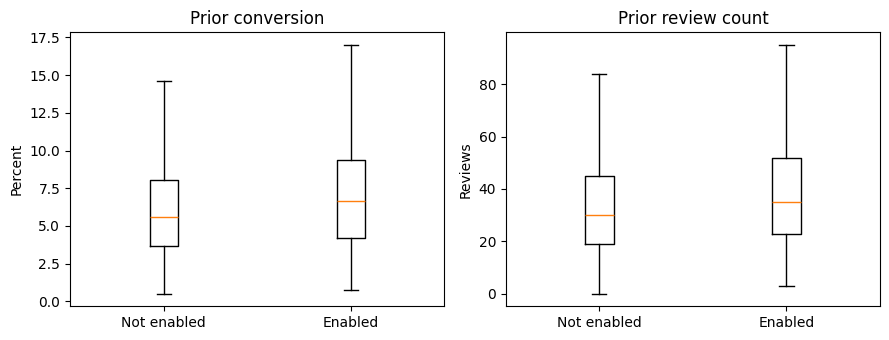

In [3]:
# Every cell recreates the same listings, so it can run independently.
rng = np.random.default_rng(42)
n = 4000
listings = pd.DataFrame({
    "review_score": np.clip(rng.normal(4.72, 0.18, n), 3.8, 5),
    "review_count": rng.negative_binomial(3, 0.08, n),
    "nightly_price": np.clip(rng.lognormal(np.log(145), 0.35, n), 55, 500),
    "host_tenure": rng.exponential(28, n),
    "prior_conversion": np.clip(rng.beta(3, 45, n), 0.005, 0.25),
})
# All five characteristics are measured before adoption.
# Stronger listings tend to enable Instant Book more often.
log_odds = (
    -3.8 + 0.55 * (listings.review_score - 4.7) / 0.18
    + 0.30 * np.log1p(listings.review_count)
    - 0.22 * (listings.nightly_price - 145) / 50
    + 0.35 * np.log1p(listings.host_tenure) / 3
    + 8 * listings.prior_conversion
)
listings["instant_book"] = rng.binomial(1, 1 / (1 + np.exp(-log_odds)))
covariates = list(listings.columns[:5])

# Compare characteristics that existed before treatment.
summary = listings.groupby("instant_book").agg(
    Listings=("instant_book", "size"),
    Prior_conversion=("prior_conversion", "mean"),
    Reviews=("review_count", "mean"),
    Price=("nightly_price", "mean"),
)
summary["Prior_conversion"] *= 100
summary.index = ["Not enabled", "Enabled"]
summary = summary.rename(columns={"Prior_conversion": "Prior conversion (%)"})
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, column, title in zip(axes, ["prior_conversion", "review_count"],
                            ["Prior conversion", "Prior review count"]):
    values = [listings.loc[listings.instant_book == t, column] for t in [0, 1]]
    if column == "prior_conversion":
        values = [v * 100 for v in values]
    ax.boxplot(values, showfliers=False)
    ax.set_xticks([1, 2], ["Not enabled", "Enabled"])
    ax.set_title(title)
    ax.set_ylabel("Percent" if column == "prior_conversion" else "Reviews")
fig.tight_layout()
summary.round(2)

the box shows different distribution between "enabled" and "not enabled" prior to conversion. 

#### Estimate propensity scores and inspect overlap
the target variable of PSM: whether this feature was enabled, NOT conversion.
Logistic Regression --> Probability. 

.fit() -> learns coefficients

.predict() -> returns probabilities. 

,count,min,median,max
Not enabled,3406,0.007,0.123,0.560
Enabled,594,0.026,0.181,0.751


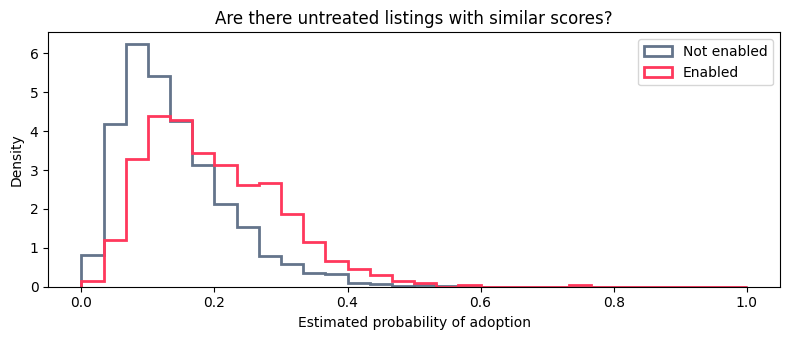

In [4]:
# Every cell recreates the same listings, so it can run independently.
rng = np.random.default_rng(42)
n = 4000
listings = pd.DataFrame({
    "review_score": np.clip(rng.normal(4.72, 0.18, n), 3.8, 5),
    "review_count": rng.negative_binomial(3, 0.08, n),
    "nightly_price": np.clip(rng.lognormal(np.log(145), 0.35, n), 55, 500),
    "host_tenure": rng.exponential(28, n),
    "prior_conversion": np.clip(rng.beta(3, 45, n), 0.005, 0.25),
})
# All five characteristics are measured before adoption.
# Stronger listings tend to enable Instant Book more often.
log_odds = (
    -3.8 + 0.55 * (listings.review_score - 4.7) / 0.18
    + 0.30 * np.log1p(listings.review_count)
    - 0.22 * (listings.nightly_price - 145) / 50
    + 0.35 * np.log1p(listings.host_tenure) / 3
    + 8 * listings.prior_conversion
)
listings["instant_book"] = rng.binomial(1, 1 / (1 + np.exp(-log_odds)))
covariates = list(listings.columns[:5])
# This predicts adoption, not future bookings. Logs capture curved patterns.
model = smf.logit(
    "instant_book ~ review_score + np.log1p(review_count) + nightly_price"
    " + np.log1p(host_tenure) + prior_conversion", data=listings,
).fit(disp=False)
listings["score"] = model.predict(listings)
treated = listings[listings.instant_book == 1]
controls = listings[listings.instant_book == 0]

# Normalize each group's histogram separately to compare score distributions.
fig, ax = plt.subplots(figsize=(8, 3.5))
bins = np.linspace(0, 1, 31)
for group, name, color in [(controls, "Not enabled", "#64748b"),
                           (treated, "Enabled", "#ff385c")]:
    ax.hist(group.score, bins=bins, density=True, histtype="step",
            linewidth=2, label=name, color=color)
ax.set(xlabel="Estimated probability of adoption", ylabel="Density",
       title="Are there untreated listings with similar scores?")
ax.legend()
fig.tight_layout()
score_summary = listings.groupby("instant_book").score.agg(["count", "min", "median", "max"])
score_summary.index = ["Not enabled", "Enabled"]
score_summary.round(3)

The median estimated score is 0.181 for adopters and 0.123 for nonadopters. Adopters were more likely to enable the feature based on their measured histories. The histograms overlap, so many adopters have potential controls.

But the highest treated score is about 0.751, while the highest control score is about 0.560. That high-score adopter has no close control. We should not force a match just to retain everyone.

High AUC is not the goal.

#### Match + Check Balance

                  Before  After
review_score       0.449  0.045
review_count       0.215 -0.024
nightly_price     -0.283  0.038
host_tenure        0.070 -0.020
prior_conversion   0.295 -0.044


,Diagnostic,Value
0,Matched treated,593.000
1,Unmatched treated,1.000
2,Unique controls,496.000
3,Maximum control reuse,6.000
4,Largest absolute SMD after,0.045


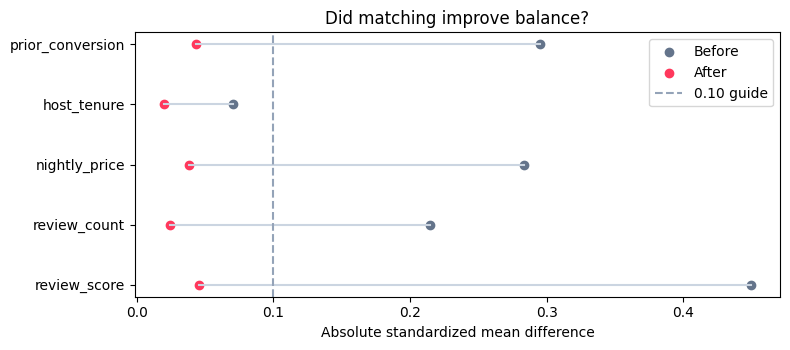

In [6]:
# Every cell recreates the same listings, so it can run independently.
rng = np.random.default_rng(42)
n = 4000
listings = pd.DataFrame({
    "review_score": np.clip(rng.normal(4.72, 0.18, n), 3.8, 5),
    "review_count": rng.negative_binomial(3, 0.08, n),
    "nightly_price": np.clip(rng.lognormal(np.log(145), 0.35, n), 55, 500),
    "host_tenure": rng.exponential(28, n),
    "prior_conversion": np.clip(rng.beta(3, 45, n), 0.005, 0.25),
})
# All five characteristics are measured before adoption.
# Stronger listings tend to enable Instant Book more often.
log_odds = (
    -3.8 + 0.55 * (listings.review_score - 4.7) / 0.18
    + 0.30 * np.log1p(listings.review_count)
    - 0.22 * (listings.nightly_price - 145) / 50
    + 0.35 * np.log1p(listings.host_tenure) / 3
    + 8 * listings.prior_conversion
)
listings["instant_book"] = rng.binomial(1, 1 / (1 + np.exp(-log_odds)))
covariates = list(listings.columns[:5])
# This predicts adoption, not future bookings. Logs capture curved patterns.
model = smf.logit(
    "instant_book ~ review_score + np.log1p(review_count) + nightly_price"
    " + np.log1p(host_tenure) + prior_conversion", data=listings,
).fit(disp=False)
listings["score"] = model.predict(listings)
treated = listings[listings.instant_book == 1]
controls = listings[listings.instant_book == 0]
# Match to the nearest score, allowing controls to be reused.
# A caliper of 0.05 means at most five points of adoption probability.
# This is an illustrative starting value, not a universal default.
def make_pairs(caliper=0.05):
    pairs = []
    for tid, score in treated["score"].items():
        distance = (controls["score"] - score).abs()
        cid = distance.idxmin()
        if distance.loc[cid] <= caliper:
            pairs.append((tid, cid))
    return pd.DataFrame(pairs, columns=["treated_id", "control_id"])

pairs = make_pairs()
if pairs.empty:
    raise ValueError("No matches. Revisit overlap and the target population.")
mt = listings.loc[pairs.treated_id]
mc = listings.loc[pairs.control_id]  # Repeated rows retain each control's weight.

# Keep the original pooled SD fixed so before/after SMDs are comparable.
scale = np.sqrt((treated[covariates].var() + controls[covariates].var()) / 2)
balance = pd.DataFrame({
    "Before": (treated[covariates].mean() - controls[covariates].mean()) / scale,
    "After": (mt[covariates].mean() - mc[covariates].mean()) / scale,
})
reuse = pairs.control_id.value_counts()

# Compare every measured characteristic, not just the propensity score.
fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(balance))
for i in y:
    ax.plot(balance.iloc[i].abs(), [i, i], color="#cbd5e1")
ax.scatter(balance.Before.abs(), y, label="Before", color="#64748b")
ax.scatter(balance.After.abs(), y, label="After", color="#ff385c")
ax.axvline(0.1, linestyle="--", color="#94a3b8", label="0.10 guide")
ax.set_yticks(y, covariates)
ax.set_xlabel("Absolute standardized mean difference")
ax.set_title("Did matching improve balance?")
ax.legend()
fig.tight_layout()
print(balance.round(3).to_string())
pd.DataFrame({
    "Diagnostic": ["Matched treated", "Unmatched treated", "Unique controls",
                   "Maximum control reuse", "Largest absolute SMD after"],
    "Value": [len(pairs), len(treated) - len(pairs), len(reuse),
              reuse.max(), round(balance.After.abs().max(), 3)],
})

We matched 593 of 594 adopters using 496 unique controls. One control appears six times. That is allowed, but those six appearances are not six independent listings.

The largest absolute SMD falls from about 0.449 to 0.045. Review-score imbalance moves from about 0.449 to 0.045; prior-conversion imbalance moves from 0.295 to about 0.044 in absolute terms. The comparison is much closer on these measured characteristics.

The 0.10 line is a diagnostic guide, not proof of causal validity. Inspect distributions and important subgroups too. If balance is poor, revise the score model or matching rules before comparing outcomes. Do not choose the match that produces the biggest treatment effect.



#### Estimate the effect and decide what it supports

Matched pairs: 593; control weight ESS: 415.2


,Estimate,Percentage points
0,Raw difference,3.04
1,Matched ATT,2.01
2,True effect,2.20


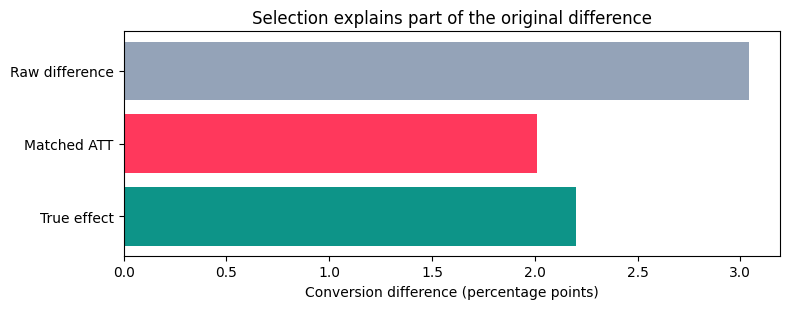

In [7]:

# Every cell recreates the same listings, so it can run independently.
rng = np.random.default_rng(42)
n = 4000
listings = pd.DataFrame({
    "review_score": np.clip(rng.normal(4.72, 0.18, n), 3.8, 5),
    "review_count": rng.negative_binomial(3, 0.08, n),
    "nightly_price": np.clip(rng.lognormal(np.log(145), 0.35, n), 55, 500),
    "host_tenure": rng.exponential(28, n),
    "prior_conversion": np.clip(rng.beta(3, 45, n), 0.005, 0.25),
})
# All five characteristics are measured before adoption.
# Stronger listings tend to enable Instant Book more often.
log_odds = (
    -3.8 + 0.55 * (listings.review_score - 4.7) / 0.18
    + 0.30 * np.log1p(listings.review_count)
    - 0.22 * (listings.nightly_price - 145) / 50
    + 0.35 * np.log1p(listings.host_tenure) / 3
    + 8 * listings.prior_conversion
)
listings["instant_book"] = rng.binomial(1, 1 / (1 + np.exp(-log_odds)))
covariates = list(listings.columns[:5])
# This predicts adoption, not future bookings. Logs capture curved patterns.
model = smf.logit(
    "instant_book ~ review_score + np.log1p(review_count) + nightly_price"
    " + np.log1p(host_tenure) + prior_conversion", data=listings,
).fit(disp=False)
listings["score"] = model.predict(listings)
treated = listings[listings.instant_book == 1]
controls = listings[listings.instant_book == 0]
# Match to the nearest score, allowing controls to be reused.
# A caliper of 0.05 means at most five points of adoption probability.
# This is an illustrative starting value, not a universal default.
def make_pairs(caliper=0.05):
    pairs = []
    for tid, score in treated["score"].items():
        distance = (controls["score"] - score).abs()
        cid = distance.idxmin()
        if distance.loc[cid] <= caliper:
            pairs.append((tid, cid))
    return pd.DataFrame(pairs, columns=["treated_id", "control_id"])

pairs = make_pairs()
if pairs.empty:
    raise ValueError("No matches. Revisit overlap and the target population.")
mt = listings.loc[pairs.treated_id]
mc = listings.loc[pairs.control_id]  # Repeated rows retain each control's weight.

# Keep the original pooled SD fixed so before/after SMDs are comparable.
scale = np.sqrt((treated[covariates].var() + controls[covariates].var()) / 2)
balance = pd.DataFrame({
    "Before": (treated[covariates].mean() - controls[covariates].mean()) / scale,
    "After": (mt[covariates].mean() - mc[covariates].mean()) / scale,
})
reuse = pairs.control_id.value_counts()

# Reveal outcomes only after defining and checking the match.
# These are simplified listing-level rates, not individual visit records.
baseline = (
    0.01 + 0.55 * listings.prior_conversion
    + 0.006 * (listings.review_score - 4.7) / 0.18
    + 0.002 * np.log1p(listings.review_count)
    - 0.00004 * (listings.nightly_price - 145)
    + rng.normal(0, 0.012, n)
)
# Construct both potential outcomes to keep the true effect exactly 0.022.
y0 = np.clip(baseline, 0, 0.978)
y1 = y0 + 0.022
listings["conversion"] = np.where(listings.instant_book == 1, y1, y0)

# Give each matched treated listing one equal-weight comparison.
pair_effects = (
    listings.loc[pairs.treated_id, "conversion"].to_numpy()
    - listings.loc[pairs.control_id, "conversion"].to_numpy()
)
raw = listings.groupby("instant_book").conversion.mean().diff().iloc[-1]
att = pair_effects.mean()

# Reused controls are not new independent observations.
control_ess = reuse.sum() ** 2 / np.square(reuse).sum()
print(f"Matched pairs: {len(pairs)}; control weight ESS: {control_ess:.1f}")

results = pd.DataFrame({
    "Estimate": ["Raw difference", "Matched ATT", "True effect"],
    "Percentage points": [100 * raw, 100 * att, 2.2],
})
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(results.Estimate, results["Percentage points"],
        color=["#94a3b8", "#ff385c", "#0d9488"])
ax.set_xlabel("Conversion difference (percentage points)")
ax.set_title("Selection explains part of the original difference")
ax.invert_yaxis()
fig.tight_layout()
# No error bars: this cell does not calculate a matching-aware interval.
results.round(2)

Before matching, Instant Book users converted 3.04 percentage points better. After comparing more similar listings, the gap fell to 2.01 points. The true effect built into this simulation is 2.20 points, so matching brought us much closer.

The drop from 3.04 to 2.01 suggests that some of the original gap came from differences the listings already had. It is not an exact measure of bias because the set of listings changed and random variation still affects the result.

There is another catch. We formed 593 pairs, but some nonuser listings were used in more than one pair. Reusing the same listing does not give us as much new information as finding a different listing. The reported value of 415, called the effective sample size, summarizes this loss of information. It is not a confidence interval.

Before acting on the result, we would calculate a confidence interval that handles reused listings and listings owned by the same host. The FAQ explains the technical options.